## Auricle: A Multimodal Wearable Sensing Dataset for Cardiovascular and Hemodynamic Assessment

### Code to Reproduce Tables and Figures

Code is organized by section and subsection. It relies on the dataset which can be found on physionet under the same name (Auricle).

### Setup

Install the notebook's third-party packages in the Python environment used by Jupyter:

`python -m pip install numpy pandas scipy wfdb matplotlib seaborn statsmodels scikit-learn ipython`

In the first code cell, set `DATASET_ROOT` to the downloaded Auricle dataset root (the folder containing `RECORDS`, `demographics.csv`, and `data/`). The default points to `../wfdb_data` for this repository checkout. The notebook generates any missing PulseKit segment CSVs alongside the WFDB sessions, then saves reproduced figures and tables directly in this paper folder.

In [1]:
# Required third-party packages: numpy, pandas, scipy, wfdb, matplotlib, seaborn,
# statsmodels, scikit-learn, and ipython. Install them with:
#     python -m pip install numpy pandas scipy wfdb matplotlib seaborn statsmodels scikit-learn ipython
from pathlib import Path
import os
import sys
import warnings

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib import gridspec
from scipy.stats import pearsonr
import wfdb

# Locate the PulseKit repository and set the Auricle dataset location here.
REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "PulseKit").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Could not find the repository folder containing PulseKit/.")

# Edit this path if the downloaded Auricle dataset is stored elsewhere.
DATASET_ROOT = Path(os.environ.get("AURICLE_DATASET_ROOT", REPO_ROOT / "wfdb_data")).expanduser().resolve()
if not (DATASET_ROOT / "RECORDS").is_file() or not (DATASET_ROOT / "data").is_dir():
    raise FileNotFoundError(
        f"Expected an Auricle dataset root containing RECORDS and data/: {DATASET_ROOT}"
    )
DATA_DIR = DATASET_ROOT / "data"
PAPER_DIR = Path(__file__).resolve().parent if "__file__" in globals() else REPO_ROOT / "Auricle Dataset Paper"
OUT_DIR = PAPER_DIR  # Save reproduced figures and tables directly beside this notebook.
OUT_DIR.mkdir(exist_ok=True, parents=True)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from PulseKit import Dataset, ECG, PPG, Stethoscope, Earbud, Accelerometer, BP, Hemodynamics, Session
from PulseKit.signal_processors.base_signal import PhysiologicalSignal
from PulseKit.signal_processors.signal_processing_utils import apply_butterworth_filter

FS = 1000
QUALITY_THRESHOLD = 0.65
WINDOW_FILE = "segments_fixed_windows_length_10_overlap_0.5.csv"
FIXED_30_FILE = "segments_fixed_windows_length_30_overlap_0.5.csv"
CYCLE_FILE = "segments_cardiac_cycles_reference_signal_name_ecg.csv"

# Read signals by WFDB channel name through PulseKit's session loader; copy arrays
# before unloading so they remain usable by the plotting cells.
def load_wfdb_channels(session_id, channel_names):
    processors = [PhysiologicalSignal(name=name) for name in channel_names]
    session = Session(session_id, processors, str(DATASET_ROOT))
    try:
        channels = {name: np.array(session.get_channel(name), copy=True) for name in channel_names}
        return channels, float(session.header.fs)
    finally:
        session.unload_session()


def participant_id(session):
    parts = str(session).split("_")
    return parts[1] if len(parts) > 1 else str(session)


def cohort_name(session):
    return "Heart failure" if str(session).startswith("HFC_") else "Healthy"


def quality_score(series):
    """Convert SQI values and validity flags to numeric scores."""
    def is_bool(value):
        return isinstance(value, (bool, np.bool_))

    bool_true = series.map(lambda value: is_bool(value) and bool(value))
    bool_false = series.map(lambda value: is_bool(value) and not bool(value))
    text = series.astype("string").str.strip().str.lower()
    result = pd.to_numeric(series, errors="coerce")
    result = result.mask(bool_true | text.eq("true"), 1.0)
    result = result.mask(bool_false | text.eq("false"), np.nan)
    return result


# Check sampling frequency from an available WFDB header.
record_entries = [line.strip().replace("\\", "/") for line in (DATASET_ROOT / "RECORDS").read_text().splitlines() if line.strip() and not line.lstrip().startswith("#")]
first_record = next((DATA_DIR / entry for entry in record_entries if (DATA_DIR / entry).with_suffix(".hea").is_file()), None)
if first_record is None:
    raise FileNotFoundError(f"No local WFDB headers were found under {DATA_DIR}.")
FS = float(wfdb.rdheader(str(first_record)).fs)

# Generate required PulseKit segment CSVs only when absent. These are analysis
# intermediates saved beside each session's WFDB files; figures/tables go to OUT_DIR.
GENERATE_MISSING_SEGMENTS = True
SEGMENT_SIGNALS = [
    "ECG", "PPG_Finger", "PPG_Ear", "Digital_Stethoscope", "Earbud_Left", "Earbud_Right",
    "Accelerometer_Z", "Diastolic_BP", "Systolic_BP", "Mean_BP", "Heart_Rate",
    "Stroke_Volume", "Cardiac_Output", "SVR",
]
SIGNAL_PROCESSORS = [
    ECG("ECG"), PPG("PPG_Finger"), PPG("PPG_Ear"), Stethoscope("Digital_Stethoscope"),
    Earbud("Earbud_Left"), Earbud("Earbud_Right"), Accelerometer("Accelerometer_Z"),
    BP("Diastolic_BP"), BP("Systolic_BP"), Hemodynamics("Mean_BP"),
    Hemodynamics("Heart_Rate"), Hemodynamics("Stroke_Volume"),
    Hemodynamics("Cardiac_Output"), Hemodynamics("SVR"),
]
LOCAL_SESSION_IDS = Dataset._discover_session_ids(str(DATASET_ROOT))
if GENERATE_MISSING_SEGMENTS:
    for session_id in LOCAL_SESSION_IDS:
        session_dir = DATA_DIR / session_id
        needed = [
            ("cycles", session_dir / CYCLE_FILE),
            ("fixed10", session_dir / WINDOW_FILE),
            ("fixed30", session_dir / FIXED_30_FILE),
        ]
        for kind, output_path in needed:
            if output_path.is_file():
                continue
            print(f"Generating {kind} segment data for {session_id}.")
            one_session = Dataset(
                datasetName="Auricle paper reproduction",
                sessionIds=[session_id],
                signals=SIGNAL_PROCESSORS,
                data_directory=str(DATASET_ROOT),
            )
            if kind == "cycles":
                one_session.get_cardiac_cycles(reference_signal_name="ECG")
            elif kind == "fixed10":
                one_session.get_fixed_windows(length=10, overlap=0.5)
            else:
                one_session.get_fixed_windows(length=30, overlap=0.5)
            one_session.process_signals(signal_list=SEGMENT_SIGNALS)

window_paths = sorted(DATA_DIR.glob(f"*/{WINDOW_FILE}"))
if not window_paths:
    raise FileNotFoundError(f"No {WINDOW_FILE} files were found or generated under {DATA_DIR}.")
window_frames = []
for csv_path in window_paths:
    session = csv_path.parent.name
    frame = pd.read_csv(csv_path)
    frame["Session"] = session
    frame["Participant"] = participant_id(session)
    frame["Cohort"] = cohort_name(session)
    window_frames.append(frame)
all_windows = pd.concat(window_frames, ignore_index=True, sort=False)
print(f"Using Auricle data at {DATASET_ROOT}")
print(f"Loaded {len(window_paths)} session files and {len(all_windows):,} 10-second windows at {FS:g} Hz.")

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
HEMO_TARGETS = ["Diastolic_BP", "Systolic_BP", "Mean_BP", "Heart_Rate", "Stroke_Volume", "Cardiac_Output", "SVR"]
HEMO_LABELS = {
    "Diastolic_BP": ("Diastolic BP", "mmHg"), "Systolic_BP": ("Systolic BP", "mmHg"),
    "Mean_BP": ("Mean BP", "mmHg"), "Heart_Rate": ("Heart rate", "beats/min"),
    "Stroke_Volume": ("Stroke volume", "mL"), "Cardiac_Output": ("Cardiac output", "L/min"),
    "SVR": ("Systemic vascular resistance", "dyn·s/cm^5"),
}
SIGNAL_COLORS = {
    "ECG": "#E6194B", "PPG_Finger": "#3CB44B", "PPG_Ear": "#BFEF45",
    "Digital_Stethoscope": "#FFE119", "Accelerometer_Z": "#469990",
    "Earbud_Left": "#911EB4", "Earbud_Right": "#F032E6",
}
SIGNAL_LABELS = {
    "ECG": "ECG", "PPG_Finger": "Finger PPG", "PPG_Ear": "Ear PPG",
    "Digital_Stethoscope": "Digital stethoscope", "Accelerometer_Z": "SCG (Z-axis)",
    "Earbud_Left": "Left earbud", "Earbud_Right": "Right earbud",
}
HEMO_MAPPING = {
    "Diastolic_BP": ("Diastolic BP", "mmHg"), "Systolic_BP": ("Systolic BP", "mmHg"),
    "Mean_BP": ("Mean BP", "mmHg"), "Heart_Rate": ("Heart Rate", "BPM"),
    "Stroke_Volume": ("Stroke Volume", "mL"), "Cardiac_Output": ("Cardiac Output", "L/min"),
    "SVR": ("Systemic Vascular Resistance", r"dyn$\\cdot$s/cm$^5$"),
}
HEMO_COLORS = {
    "Diastolic_BP": "#000075", "Systolic_BP": "#800000", "Mean_BP": "#9A6324",
    "Heart_Rate": "#808000", "Stroke_Volume": "#005A32", "Cardiac_Output": "#4B0082",
    "SVR": "#A52A2A", "NIBP": "#2F4F4F",
}


Skipping 102 RECORDS entries without a local WFDB header (for example: HC_11_1, HC_11_2, HC_12_1, HC_12_2, HC_13_1).
Generating fixed10 segment data for HC_10_1.
Using segments file: segments_fixed_windows_length_10_overlap_0.5.csv
Processing session HC_10_1...
Generating fixed30 segment data for HC_10_1.
Using segments file: segments_fixed_windows_length_30_overlap_0.5.csv
Processing session HC_10_1...
Generating fixed10 segment data for HC_10_2.
Using segments file: segments_fixed_windows_length_10_overlap_0.5.csv
Processing session HC_10_2...
Generating fixed30 segment data for HC_10_2.
Using segments file: segments_fixed_windows_length_30_overlap_0.5.csv
Processing session HC_10_2...
Generating fixed10 segment data for HC_42_2.
Using segments file: segments_fixed_windows_length_10_overlap_0.5.csv
Processing session HC_42_2...
Generating fixed30 segment data for HC_42_2.
Using segments file: segments_fixed_windows_length_30_overlap_0.5.csv
Processing session HC_42_2...
Generating fi

In [6]:
# Keep BASE_DIR as a compatibility alias for paper-analysis sections, and ensure
# all required analysis columns exist even when segment CSVs were made by an older version.
BASE_DIR = DATASET_ROOT
REQUIRED_CYCLE_COLUMNS = {
    *(f"{name}_quality" for name in SEGMENT_SIGNALS),
    *(f"{name}_midpoint" for name in HEMO_TARGETS),
}
for session_id in LOCAL_SESSION_IDS:
    session_dir = DATA_DIR / session_id
    cycle_path = session_dir / CYCLE_FILE
    cycle_columns = set(pd.read_csv(cycle_path, nrows=0).columns) if cycle_path.is_file() else set()
    if not REQUIRED_CYCLE_COLUMNS.issubset(cycle_columns):
        print(f"Generating complete cardiac-cycle measurements for {session_id}.")
        cycle_dataset = Dataset(
            datasetName="Auricle paper cardiac-cycle update",
            sessionIds=[session_id],
            signals=SIGNAL_PROCESSORS,
            data_directory=str(DATASET_ROOT),
        )
        cycle_dataset.get_cardiac_cycles(reference_signal_name="ECG")
        cycle_dataset.process_signals(signal_list=SEGMENT_SIGNALS)

    for length, filename in ((10, WINDOW_FILE), (30, FIXED_30_FILE)):
        csv_path = session_dir / filename
        columns = set(pd.read_csv(csv_path, nrows=0).columns) if csv_path.is_file() else set()
        if "NIBP_quality" in columns:
            continue
        print(f"Adding NIBP quality data to {filename} for {session_id}.")
        nibp_dataset = Dataset(
            datasetName="Auricle paper NIBP quality update",
            sessionIds=[session_id],
            signals=[BP("NIBP")],
            data_directory=str(DATASET_ROOT),
        )
        nibp_dataset.get_fixed_windows(length=length, overlap=0.5)
        nibp_dataset.process_signals(signal_list=["NIBP"])

window_paths = sorted(DATA_DIR.glob(f"*/{WINDOW_FILE}"))
window_frames = []
for csv_path in window_paths:
    session = csv_path.parent.name
    frame = pd.read_csv(csv_path)
    frame["Session"] = session
    frame["Participant"] = participant_id(session)
    frame["Cohort"] = cohort_name(session)
    window_frames.append(frame)
all_windows = pd.concat(window_frames, ignore_index=True, sort=False)


Generating complete cardiac-cycle measurements for HC_10_1.
Using segments file: segments_cardiac_cycles_reference_signal_name_ecg.csv
Processing session HC_10_1...
Generating complete cardiac-cycle measurements for HC_10_2.
Using segments file: segments_cardiac_cycles_reference_signal_name_ecg.csv
Processing session HC_10_2...
Generating complete cardiac-cycle measurements for HC_42_2.
Using segments file: segments_cardiac_cycles_reference_signal_name_ecg.csv
Processing session HC_42_2...
Generating complete cardiac-cycle measurements for HFC_106_1.
Using segments file: segments_cardiac_cycles_reference_signal_name_ecg.csv
Processing session HFC_106_1...
Generating complete cardiac-cycle measurements for HFC_116_1.
Using segments file: segments_cardiac_cycles_reference_signal_name_ecg.csv
Processing session HFC_116_1...


### 2. Methods

#### 2.1 Participants

Table 1: Demographics Table

In [3]:
demographics = pd.read_csv(DATASET_ROOT / "demographics.csv")
demographics["Participant"] = pd.to_numeric(demographics["Participant"], errors="coerce")
demographics["Cohort"] = np.where(demographics["Participant"] >= 100, "Heart failure", "Healthy")
# Support current Auricle metadata names as well as older releases.
demographics = demographics.rename(columns={"Height (cm)": "Height", "Weight (kg)": "Weight"})
for col in ["Age", "Height", "Weight"]:
    demographics[col] = pd.to_numeric(demographics[col], errors="coerce")
demographics["LVEF_numeric"] = pd.to_numeric(
    demographics["LV ejection fraction"].astype(str).str.replace("%", "", regex=False),
    errors="coerce",
)


def mean_sd(values, digits=1):
    values = pd.to_numeric(values, errors="coerce").dropna()
    if values.empty:
        return "NA"
    return f"{values.mean():.{digits}f} ± {values.std():.{digits}f}"


demo_rows = []
for group in ["Healthy", "Heart failure"]:
    data = demographics.loc[demographics["Cohort"] == group].copy()
    female_n = data["Gender"].astype(str).str.lower().eq("female").sum()
    nyha_counts = data["NYHA Class"].dropna().astype(str).value_counts().sort_index()
    nyha_text = "; ".join(f"{level}: {count}" for level, count in nyha_counts.items()) or "NA"
    demo_rows.append({
        "Cohort": group,
        "Participants, n": data["Participant"].nunique(),
        "Age, years": mean_sd(data["Age"]),
        "Female, n (%)": f"{female_n} ({100 * female_n / max(len(data), 1):.1f}%)",
        "Height, cm": mean_sd(data["Height"]),
        "Weight, kg": mean_sd(data["Weight"]),
        "LVEF, %": mean_sd(data["LVEF_numeric"]),
        "NYHA class, n": nyha_text,
    })
demographics_table = pd.DataFrame(demo_rows).set_index("Cohort")
demographics_table.to_csv(OUT_DIR / "table_1_demographics.csv")
print("Table 1. Cohort demographics (continuous values are mean ± SD).")
display(demographics_table)
print(f"Saved: {OUT_DIR / 'table_1_demographics.csv'}")

Table 1. Cohort demographics (continuous values are mean ± SD).


,"Participants, n","Age, years","Female, n (%)","Height, cm","Weight, kg","LVEF, %","NYHA class, n"
Cohort,,,,,,,
Healthy,42,27.4 ± 9.5,21 (50.0%),171.0 ± 9.2,71.4 ± 16.9,NA,NA
Heart failure,28,51.2 ± 15.1,8 (28.6%),170.1 ± 10.6,82.9 ± 19.9,39.5 ± 13.0,1: 14; 2: 8; 3: 3; 4: 1; NOT FOUND: 2


Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/table_1_demographics.csv


#### 2.2 Hardware Description

Figure 1: Anatomical sensor placement diagram with example signal clip

HC_10_2 / window 58; minimum core-signal SQI=0.583; displaying 3 s from +3 to +6 s.


/var/folders/qj/v5vpz3c169506rzn5tfshb0h0000gn/T/ipykernel_7761/718989054.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


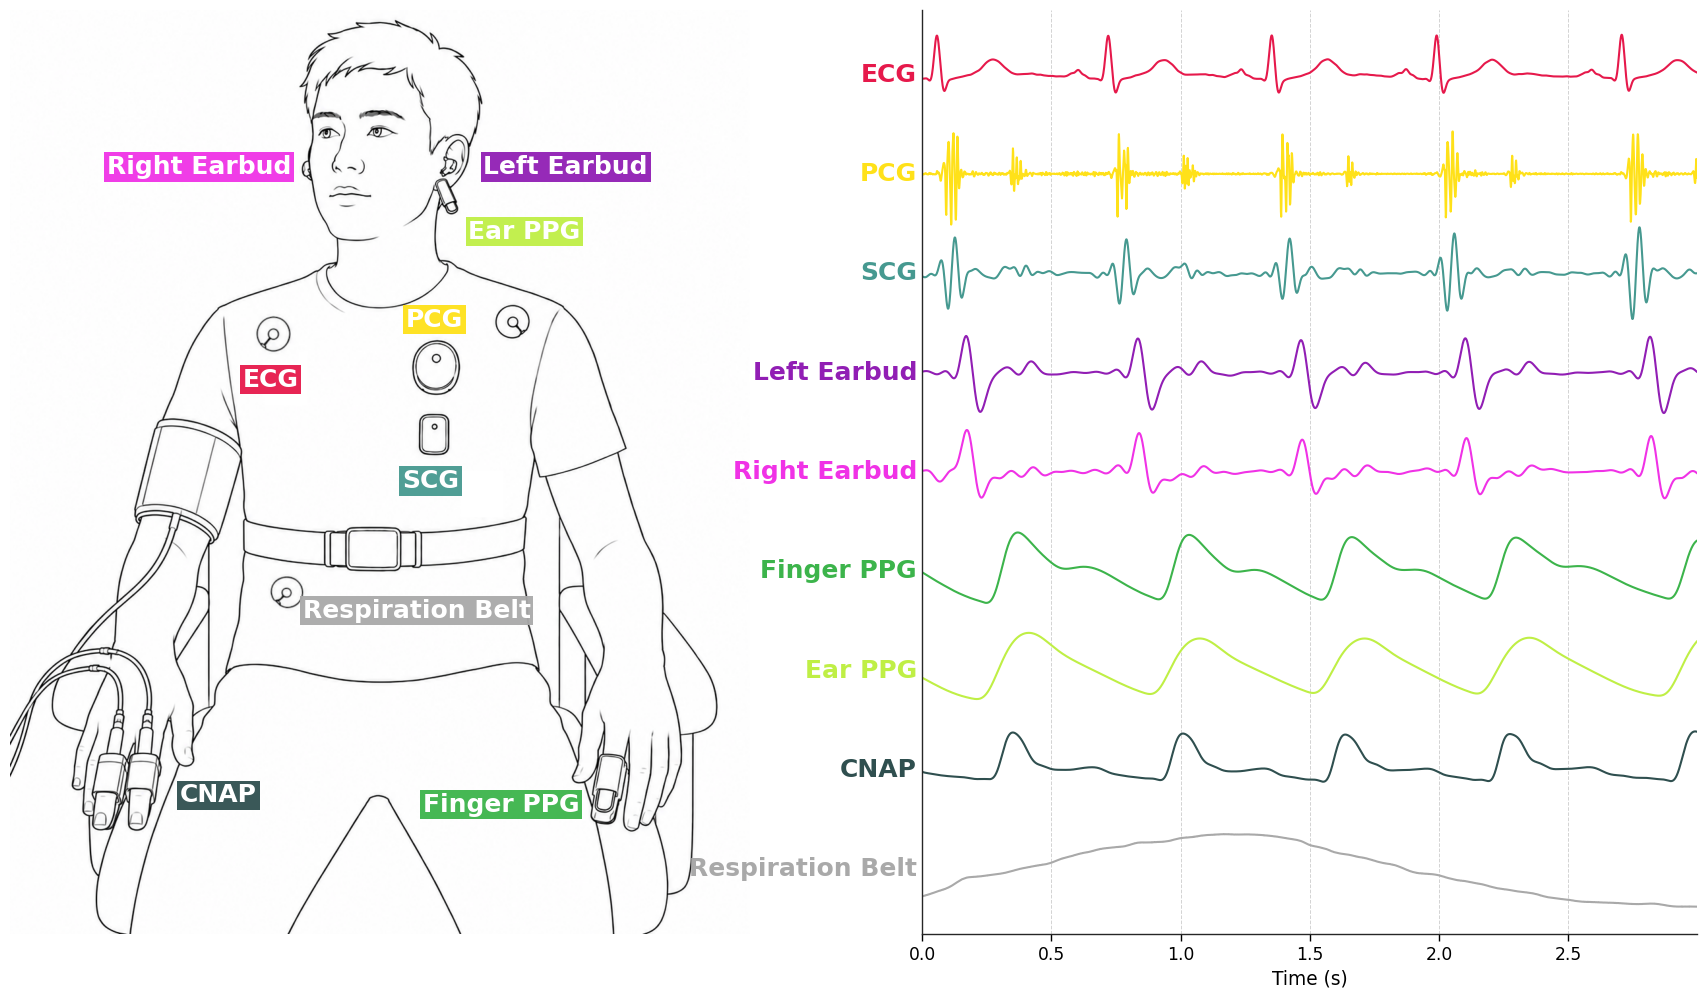

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_1_sensors.png


In [16]:
TARGET_SESSION = "HC_10_2"
TARGET_WINDOW_ID = 58
DISPLAY_SECONDS = 3
CLIP_OFFSET_SECONDS = 3
TRACE_SCALE = 0.75
TRACE_SPACING = 2.0
MODALITY_DATA = {
    "ECG": {"signal": "ECG"}, "PCG": {"signal": "Digital_Stethoscope"},
    "SCG": {"signal": "Accelerometer_Z"}, "Left Earbud": {"signal": "Earbud_Left"},
    "Right Earbud": {"signal": "Earbud_Right"}, "Finger PPG": {"signal": "PPG_Finger"},
    "Ear PPG": {"signal": "PPG_Ear"}, "CNAP": {"signal": "NIBP"},
    "Respiration Belt": {"signal": "Respiration_Belt"},
}
MODALITY_COLORS = {
    "ECG": "#E6194B", "PCG": "#FFE119", "SCG": "#469990", "Left Earbud": "#911EB4",
    "Right Earbud": "#F032E6", "Finger PPG": "#3CB44B", "Ear PPG": "#BFEF45",
    "CNAP": "#2F4F4F", "Respiration Belt": "#A9A9A9",
}
SENSOR_IMAGE_LABEL_POSITIONS = {
    "PCG": (0.315, 0.665), "ECG": (0.61, 0.60), "SCG": (0.31, 0.49),
    "Left Earbud": (0.42, 0.83), "Right Earbud": (0.60, 0.83),
    "Finger PPG": (0.99, 0.14), "Ear PPG": (0.40, 0.76), "CNAP": (0.01, 0.15),
    "Respiration Belt": (0.33, 0.35),
}
SENSOR_IMAGE_LABEL_ALIGNMENTS = {
    "PCG": "left", "ECG": "right", "SCG": "left", "Left Earbud": "left",
    "Right Earbud": "right", "Finger PPG": "right", "Ear PPG": "left",
    "CNAP": "left", "Respiration Belt": "center",
}
FILTER_SETTINGS = {
    "ECG": (0.5, 40.0), "Digital_Stethoscope": (40.0, 240.0),
    "Accelerometer_Z": (0.8, 25.0), "Earbud_Left": (0.5, 15.0),
    "Earbud_Right": (0.5, 15.0), "PPG_Finger": (0.5, 15.0),
    "PPG_Ear": (0.5, 15.0), "NIBP": (0.5, 15.0), "Respiration_Belt": None,
}

session_dir = DATA_DIR / TARGET_SESSION
fixed_df = pd.read_csv(session_dir / FIXED_30_FILE)
quality_row = fixed_df.loc[fixed_df["window_id"].eq(TARGET_WINDOW_ID)]
if quality_row.empty:
    raise ValueError(f"Window {TARGET_WINDOW_ID} not found in {TARGET_SESSION}.")
selection_signals = ["ECG", "Digital_Stethoscope", "Accelerometer_Z", "Earbud_Left", "Earbud_Right", "PPG_Finger", "PPG_Ear"]
quality_columns = [f"{name}_quality" for name in selection_signals if f"{name}_quality" in fixed_df]
minimum_quality = pd.to_numeric(quality_row.iloc[0][quality_columns], errors="coerce").min()
SAMPLING_RATE = FS
window_start = int(quality_row.iloc[0]["start"])
clip_start = window_start + int(CLIP_OFFSET_SECONDS * SAMPLING_RATE)
clip_end = min(int(quality_row.iloc[0]["end"]), clip_start + int(DISPLAY_SECONDS * SAMPLING_RATE))
time_vector = (np.arange(clip_start, clip_end) - clip_start) / SAMPLING_RATE


def load_filtered_trace(raw, signal_name):
    raw = np.asarray(raw, dtype=float).squeeze()
    settings = FILTER_SETTINGS[signal_name]
    if settings is None:
        return raw
    lowcut, highcut = settings
    filtered = apply_butterworth_filter(raw, lowcut, "high", SAMPLING_RATE, order=5)
    filtered = apply_butterworth_filter(filtered, highcut, "low", SAMPLING_RATE, order=5)
    return filtered if np.ptp(filtered) > 0 else raw


def normalize_trace(trace):
    trace = np.asarray(trace, dtype=float)
    finite = trace[np.isfinite(trace)]
    if not len(finite):
        return np.zeros_like(trace)
    trace = np.nan_to_num(trace - np.median(finite))
    amplitude = np.percentile(np.abs(trace), 99)
    return trace / amplitude if amplitude > 0 else trace


channel_names = [config["signal"] for config in MODALITY_DATA.values()]
channels, session_fs = load_wfdb_channels(TARGET_SESSION, channel_names)
if not np.isclose(session_fs, SAMPLING_RATE):
    raise ValueError(f"Sample rate mismatch: configured {SAMPLING_RATE:g} Hz, record has {session_fs:g} Hz")
cycle_data = {}
for modality, config in MODALITY_DATA.items():
    signal_name = config["signal"]
    filtered = load_filtered_trace(channels[signal_name], signal_name)
    cycle_data[modality] = normalize_trace(filtered[clip_start:clip_end])
available_modalities = [name for name in MODALITY_DATA if name in cycle_data]
print(f"{TARGET_SESSION} / window {TARGET_WINDOW_ID}; minimum core-signal SQI={minimum_quality:.3f}; displaying 3 s from +3 to +6 s.")

fig = plt.figure(figsize=(22, 12), dpi=100)
grid = fig.add_gridspec(1, 2, width_ratios=[1, 1], wspace=0.2)
ax_person, ax_signal = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])
ax_person.imshow(mpimg.imread(PAPER_DIR / "collection_diagram.png"))
ax_person.set_aspect("equal")
ax_person.set_xticks([])
ax_person.set_yticks([])
for spine in ax_person.spines.values():
    spine.set_visible(False)
ax_signal.set_yticks([])
ax_signal.spines["top"].set_visible(False)
ax_signal.spines["right"].set_visible(False)
for modality in available_modalities:
    x_pos, y_pos = SENSOR_IMAGE_LABEL_POSITIONS[modality]
    ax_person.text(x_pos + (0.22 if x_pos <= 0.5 else -0.22), y_pos, modality,
                   transform=ax_person.transAxes, color="white", fontsize=18,
                   fontweight="bold", ha=SENSOR_IMAGE_LABEL_ALIGNMENTS[modality], va="center",
                   bbox={"facecolor": MODALITY_COLORS[modality], "alpha": 0.95, "edgecolor": "none", "pad": 2})
for index, modality in enumerate(available_modalities):
    offset = -TRACE_SPACING * index
    ax_signal.plot(time_vector, cycle_data[modality] * TRACE_SCALE + offset,
                   color=MODALITY_COLORS[modality], linewidth=1.5, zorder=2)
    ax_signal.text(time_vector.min() - 0.02, offset, modality, color=MODALITY_COLORS[modality],
                   ha="right", va="center", fontweight="bold", fontsize=18)
ax_signal.set_xlabel("Time (s)")
ax_signal.set_xlim(time_vector.min(), time_vector.max())
ax_signal.set_ylim(-(len(available_modalities) - 1) * TRACE_SPACING - TRACE_SPACING * 0.65, TRACE_SPACING * 0.65)
ax_signal.set_yticks([])
ax_signal.grid(axis="x", color="lightgrey", linestyle="--", linewidth=0.7)
fig.tight_layout()
fig.savefig(OUT_DIR / "figure_1_sensors.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_DIR / 'figure_1_sensors.png'}")

### 4. Technical Validation

#### 4.1 Distribution of Hemodynamic Parameters

Figure 3: Hemodynamic distributions by cohort

In [13]:
# Use plain-text units to avoid Matplotlib mathtext parsing differences across releases.
HEMO_MAPPING["SVR"] = ("Systemic Vascular Resistance", "dyn·s/cm⁵")


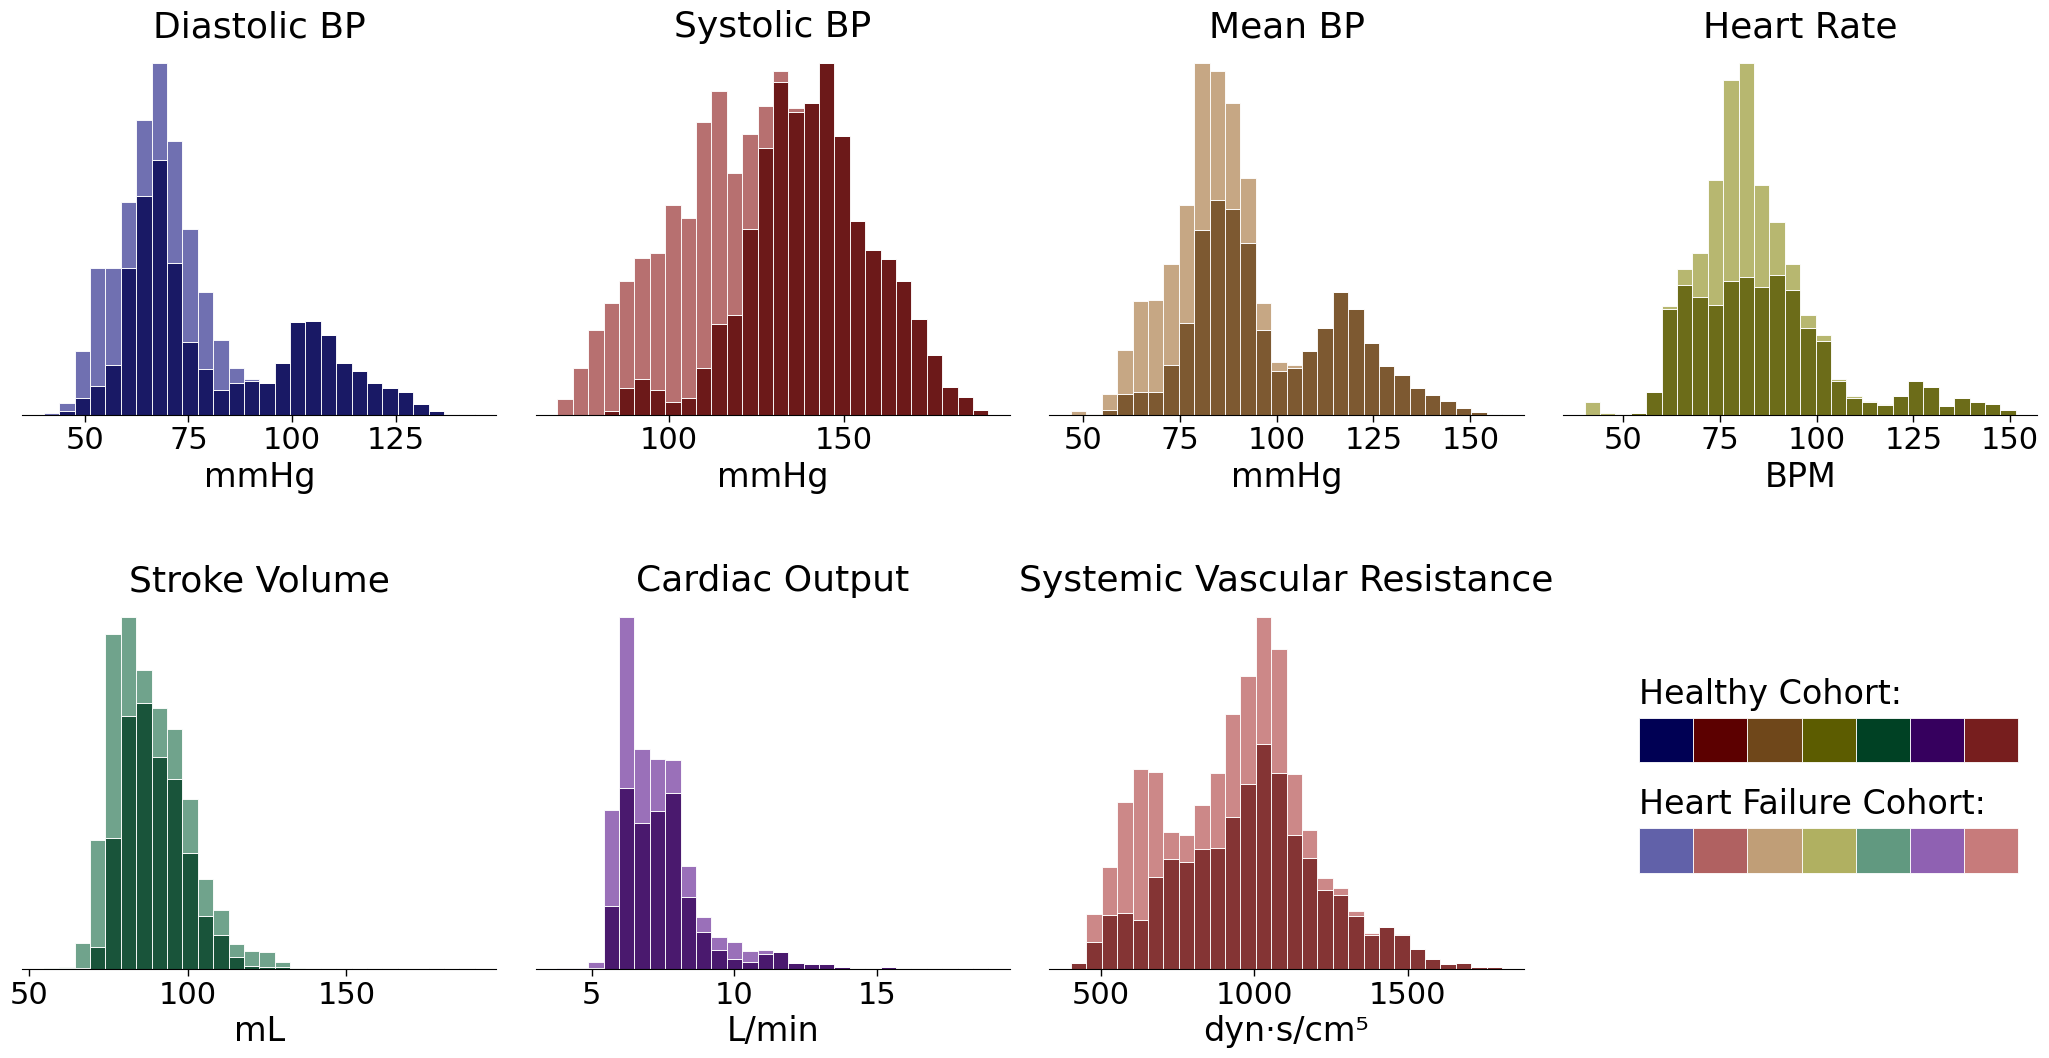

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_3_hemodynamics.png


In [14]:
PHYSIOLOGICAL_VALID_RANGES = {
    "Diastolic_BP": (30, 150), "Systolic_BP": (60, 250), "Mean_BP": (40, 180),
    "Heart_Rate": (40, 180), "Stroke_Volume": (20, 200),
    "Cardiac_Output": (1.5, 19), "SVR": (400, 2900),
}

cycle_files = sorted(DATA_DIR.glob(f"*/{CYCLE_FILE}"))
if not cycle_files:
    raise FileNotFoundError(f"No cardiac-cycle CSVs found under {DATA_DIR}.")

cycle_frames = []
for path in cycle_files:
    cohort = "Heart Failure" if path.parent.name.startswith("HFC_") else "Healthy"
    frame = pd.read_csv(path)
    if not {"Diastolic_BP_quality", "Systolic_BP_quality"}.issubset(frame.columns):
        continue
    bp_valid = frame["Diastolic_BP_quality"].isin([True, "True", "true", 1, 1.0]) & frame["Systolic_BP_quality"].isin([True, "True", "true", 1, 1.0])
    value_cols = [f"{name}_midpoint" for name in HEMO_TARGETS if f"{name}_midpoint" in frame.columns]
    if not value_cols:
        continue
    part = frame.loc[bp_valid, value_cols].copy()
    part["Group"] = cohort
    cycle_frames.append(part)

if not cycle_frames:
    raise ValueError("No valid hemodynamic cycle measurements available.")
hemo_df = pd.concat(cycle_frames, ignore_index=True)
midpoint_cols = [f"{target}_midpoint" for target in HEMO_TARGETS if f"{target}_midpoint" in hemo_df.columns]
hemo_targets = [col.replace("_midpoint", "") for col in midpoint_cols]
target_colors = [HEMO_COLORS[target] for target in hemo_targets]

def make_shades(hex_color):
    rgb = np.array(plt.matplotlib.colors.to_rgb(hex_color))
    return np.clip(rgb * 0.72, 0, 1), np.clip(1 - (1 - rgb) * 0.62, 0, 1)

fig = plt.figure(figsize=(26, 12), facecolor="white")
gs = fig.add_gridspec(nrows=2, ncols=12, hspace=0.5, wspace=0.3)
axes = [fig.add_subplot(gs[0, 0:3]), fig.add_subplot(gs[0, 3:6]), fig.add_subplot(gs[0, 6:9]),
        fig.add_subplot(gs[0, 9:12]), fig.add_subplot(gs[1, 0:3]), fig.add_subplot(gs[1, 3:6]),
        fig.add_subplot(gs[1, 6:9])]
legend_ax = fig.add_subplot(gs[1, 9:12])
legend_ax.axis("off")

for i, (col, target_name) in enumerate(zip(midpoint_cols, hemo_targets)):
    ax = axes[i]
    ax.set_facecolor("white")
    ax.grid(False)
    clean_title, unit = HEMO_MAPPING.get(target_name, (target_name.replace("_", " "), "Units"))
    healthy_vals = pd.to_numeric(hemo_df.loc[hemo_df["Group"] == "Healthy", col], errors="coerce").dropna()
    hf_vals = pd.to_numeric(hemo_df.loc[hemo_df["Group"] == "Heart Failure", col], errors="coerce").dropna()
    if target_name in PHYSIOLOGICAL_VALID_RANGES:
        min_val, max_val = PHYSIOLOGICAL_VALID_RANGES[target_name]
        healthy_vals = healthy_vals[(healthy_vals >= min_val) & (healthy_vals <= max_val)]
        hf_vals = hf_vals[(hf_vals >= min_val) & (hf_vals <= max_val)]
    combined = pd.concat([healthy_vals, hf_vals], ignore_index=True)
    if combined.empty:
        ax.text(0.5, 0.5, "No data", ha="center", va="center", transform=ax.transAxes, fontsize=22)
        ax.set_title(clean_title, fontsize=26, fontweight="semibold")
        ax.set_xlabel(unit, fontsize=22)
    else:
        dark_shade, light_shade = make_shades(target_colors[i])
        ax.hist([healthy_vals, hf_vals], bins=28, stacked=True,
                color=[dark_shade, light_shade], alpha=0.9, edgecolor="white", linewidth=0.7)
        ax.set_title(clean_title, fontsize=26)
        ax.set_xlabel(unit, fontsize=24)
    ax.set_ylabel("")
    ax.set_yticks([])
    ax.tick_params(axis="y", left=False, labelleft=False)
    ax.tick_params(axis="x", labelsize=22)
    for side in ("left", "top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("black")
    ax.spines["bottom"].set_linewidth(0.8)

dark_shades = [make_shades(color)[0] for color in target_colors]
light_shades = [make_shades(color)[1] for color in target_colors]
x0, bar_h, bar_w = 0.16, 0.12, 0.8
seg_w = bar_w / max(len(target_colors), 1)
y_light, y_dark = 0.26, 0.56
for j, (dark, light) in enumerate(zip(dark_shades, light_shades)):
    xj = x0 + j * seg_w
    legend_ax.add_patch(plt.Rectangle((xj, y_dark), seg_w, bar_h, transform=legend_ax.transAxes, facecolor=dark, edgecolor="white", linewidth=0.6))
    legend_ax.add_patch(plt.Rectangle((xj, y_light), seg_w, bar_h, transform=legend_ax.transAxes, facecolor=light, edgecolor="white", linewidth=0.6))
legend_ax.text(x0, y_dark + bar_h + 0.02, "Healthy Cohort:", transform=legend_ax.transAxes, ha="left", va="bottom", fontsize=24)
legend_ax.text(x0, y_light + bar_h + 0.02, "Heart Failure Cohort:", transform=legend_ax.transAxes, ha="left", va="bottom", fontsize=24)

fig.savefig(OUT_DIR / "target_distributions_cohorts.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
fig.savefig(OUT_DIR / "figure_3_hemodynamics.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {OUT_DIR / 'figure_3_hemodynamics.png'}")

Table 2: Hemodynamic parameters across activities

In [15]:
PHYSIOLOGICAL_VALID_RANGES = {
    "Diastolic_BP": (30, 150), "Systolic_BP": (60, 250), "Mean_BP": (40, 180),
    "Heart_Rate": (40, 200), "Stroke_Volume": (20, 200),
    "Cardiac_Output": (1.5, 19), "SVR": (400, 2900),
}
ACTIVITY_LABELS = {0: "Rest", 1: "Breath Hold", 2: "Valsalva", 3: "Exercise", 4: "Cold Pressor"}


def fmt_mean_sd(series):
    return "-" if len(series) == 0 else f"{series.mean():.1f} ± {series.std():.1f}"


activity_windows = []
for session, session_data in all_windows.groupby("Session", sort=False):
    try:
        channel, _ = load_wfdb_channels(session, ["Activity_Annotations"])
        activity_mask = channel["Activity_Annotations"].squeeze()
    except (FileNotFoundError, ValueError, KeyError) as exc:
        print(f"Skipping activity annotations for {session}: {exc}")
        continue
    phases = []
    for _, row in session_data.iterrows():
        start = pd.to_numeric(row.get("start"), errors="coerce")
        end = pd.to_numeric(row.get("end"), errors="coerce")
        if pd.isna(start) or pd.isna(end):
            phases.append(None)
            continue
        start, end = max(0, int(start)), min(len(activity_mask), int(end))
        window_codes = np.asarray(activity_mask[start:end])
        window_codes = window_codes[np.isfinite(window_codes)]
        if start >= end or window_codes.size == 0:
            phases.append(None)
            continue
        codes, counts = np.unique(np.rint(window_codes).astype(int), return_counts=True)
        phases.append(ACTIVITY_LABELS.get(int(codes[np.argmax(counts)])))
    session_data = session_data.copy()
    session_data["Activity"] = phases
    activity_windows.append(session_data)
if not activity_windows:
    raise FileNotFoundError("No usable WFDB Activity_Annotations channels were found.")
activity_windows = pd.concat(activity_windows, ignore_index=True)

activity_long_parts = []
filtering_stats = {}
for target in HEMO_TARGETS:
    value_col, quality_col = f"{target}_midpoint", f"{target}_quality"
    if value_col not in activity_windows.columns:
        continue
    keep_cols = ["Participant", "Session", "Cohort", "Activity", value_col]
    if quality_col in activity_windows.columns:
        keep_cols.append(quality_col)
    part = activity_windows[keep_cols].copy()
    part["value"] = pd.to_numeric(part[value_col], errors="coerce")
    if quality_col in part.columns:
        part = part.loc[quality_score(part[quality_col]) >= QUALITY_THRESHOLD]
    part = part.dropna(subset=["value", "Activity"])
    initial_len = len(part)
    if target in PHYSIOLOGICAL_VALID_RANGES:
        min_val, max_val = PHYSIOLOGICAL_VALID_RANGES[target]
        part = part[(part["value"] >= min_val) & (part["value"] <= max_val)]
    filtering_stats[target] = {
        "initial": initial_len, "removed": initial_len - len(part),
        "percent": (initial_len - len(part)) / initial_len * 100 if initial_len else 0,
    }
    part["Parameter"] = target
    activity_long_parts.append(part.groupby(["Participant", "Session", "Cohort", "Activity", "Parameter"], as_index=False)["value"].mean())
    overall = part.groupby(["Participant", "Session", "Cohort", "Parameter"], as_index=False)["value"].mean()
    overall["Activity"] = "Overall"
    activity_long_parts.append(overall)
if not activity_long_parts:
    raise ValueError("No hemodynamic midpoint columns were found in 10-second segments.")
activity_long = pd.concat(activity_long_parts, ignore_index=True)
HEMO_LABELS_FMT = {
    "Diastolic_BP": "Diastolic BP (mmHg)", "Systolic_BP": "Systolic BP (mmHg)",
    "Mean_BP": "Mean BP (mmHg)", "Heart_Rate": "Heart Rate (BPM)",
    "Stroke_Volume": "Stroke Volume (mL)", "Cardiac_Output": "Cardiac Output (L/min)",
    "SVR": "Systemic Vascular Resistance (dyn·s/cm⁵)",
}
activity_order = list(ACTIVITY_LABELS.values()) + ["Overall"]
final_rows = [{"Parameter": "Healthy Cohort", **{activity: "" for activity in activity_order}}]
for target in HEMO_TARGETS:
    row = {"Parameter": HEMO_LABELS_FMT.get(target, target)}
    for activity in activity_order:
        subset = activity_long.loc[(activity_long["Parameter"] == target) & (activity_long["Activity"] == activity)].copy()
        healthy_vals = subset.loc[subset["Cohort"].eq("Healthy"), "value"]
        value_text = fmt_mean_sd(healthy_vals)
        if activity == "Overall" and subset["Participant"].nunique() >= 4 and subset.groupby("Cohort")["Participant"].nunique().min() >= 2:
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    fit = smf.mixedlm("value ~ C(Cohort)", data=subset, groups=subset["Participant"]).fit(reml=False, method="lbfgs", disp=False)
                p_value = float(fit.pvalues.get("C(Cohort)[T.Heart failure]", np.nan))
                value_text += " ***" if p_value < 0.001 else " **" if p_value < 0.01 else " *" if p_value < 0.05 else ""
            except Exception as exc:
                print(f"Mixed model skipped for {target} / {activity}: {exc}")
        row[activity] = value_text
    final_rows.append(row)
final_rows.append({"Parameter": "Heart Failure Cohort", **{activity: "" for activity in activity_order}})
for target in HEMO_TARGETS:
    row = {"Parameter": HEMO_LABELS_FMT.get(target, target)}
    for activity in activity_order:
        subset = activity_long.loc[(activity_long["Parameter"] == target) & (activity_long["Activity"] == activity)]
        # Dataset helper retains the existing title-case convention: "Heart failure".
        row[activity] = fmt_mean_sd(subset.loc[subset["Cohort"].eq("Heart failure"), "value"])
    final_rows.append(row)

activity_table = pd.DataFrame(final_rows)
activity_table.to_csv(OUT_DIR / "table_2_hemodynamics.csv", index=False)
print("Table 2. Hemodynamics across activity phases (mean ± SD). Stars mark cohort differences: * p<.05, ** p<.01, *** p<.001.")
display(activity_table)
print(f"Saved: {OUT_DIR / 'table_2_hemodynamics.csv'}")

Table 2. Hemodynamics across activity phases (mean ± SD). Stars mark cohort differences: * p<.05, ** p<.01, *** p<.001.


,Parameter,Rest,Breath Hold,Valsalva,Exercise,Cold Pressor,Overall
0,Healthy Cohort,,,,,,
1,Diastolic BP (mmHg),79.6 ± 23.2,76.0 ± 18.7,81.1 ± 18.1,84.1 ± 24.2,89.5 ± 28.2,81.1 ± 23.4
2,Systolic BP (mmHg),138.7 ± 17.6,136.2 ± 15.7,138.3 ± 5.3,149.5 ± 12.5,147.3 ± 16.9,140.5 ± 15.7 ***
3,Mean BP (mmHg),96.8 ± 19.8,92.8 ± 15.4,94.5 ± 13.1,102.0 ± 21.6,107.7 ± 25.5,98.1 ± 19.6
4,Heart Rate (BPM),81.7 ± 10.1,74.2 ± 7.9,78.5 ± 8.7,113.5 ± 23.8,88.6 ± 17.0,84.7 ± 12.1
5,Stroke Volume (mL),91.7 ± 6.0,90.9 ± 2.6,85.3 ± 2.4,96.1 ± 19.2,86.2 ± 11.5,90.7 ± 5.7
6,Cardiac Output (L/min),7.5 ± 0.9,6.7 ± 0.5,6.7 ± 0.8,10.6 ± 2.9,7.5 ± 0.7,7.6 ± 1.0
7,Systemic Vascular Resistance (dyn·s/cm⁵),999.3 ± 195.2,1023.5 ± 215.2,1045.7 ± 220.1,881.9 ± 34.8,1073.8 ± 243.0,1004.3 ± 189.0
8,Heart Failure Cohort,,,,,,
9,Diastolic BP (mmHg),64.6 ± 13.0,64.1 ± nan,72.6 ± nan,70.7 ± 11.2,-,65.0 ± 12.3


Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/table_2_hemodynamics.csv


#### 4.2 Distribution of Physiological Signal Quality Index

Figure 4: Representative SQI thresholds

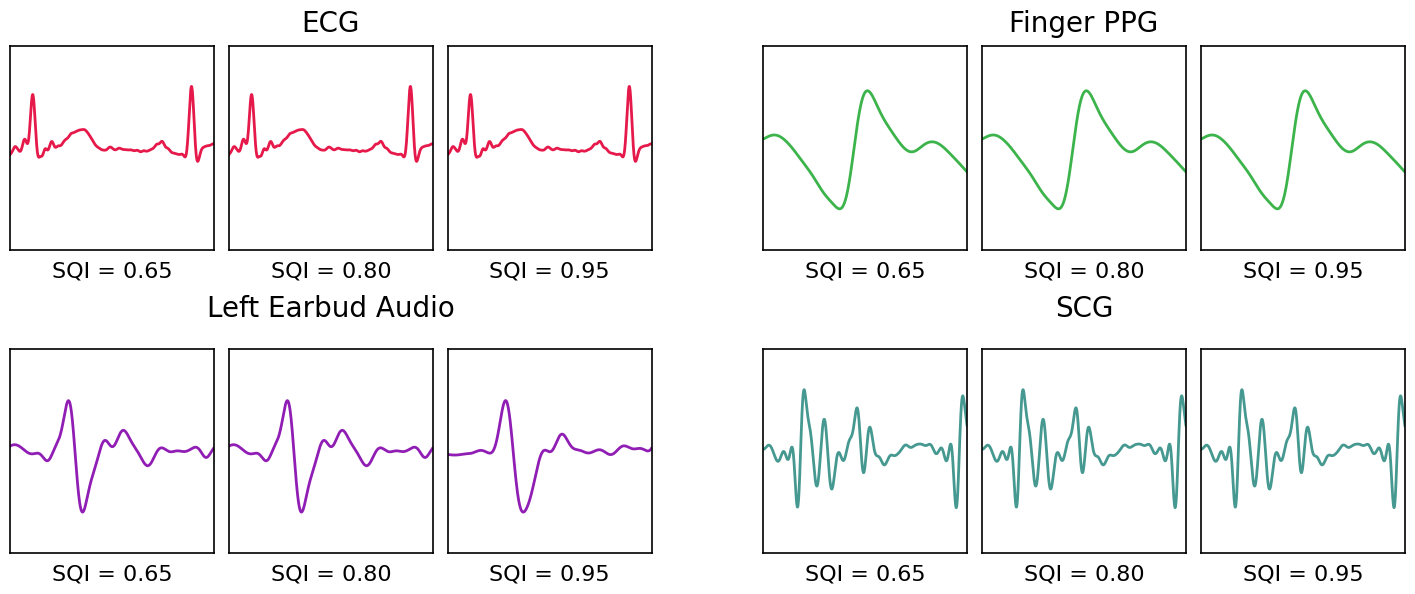

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_4_sqi_examples.png


In [17]:
MANUAL_CYCLE_SELECTIONS = {
    ("ECG", 0.65): ("HC_4_2", 117), ("ECG", 0.80): ("HC_8_2", 393), ("ECG", 0.95): ("HC_17", 249),
    ("PPG_Finger", 0.65): ("HC_3_2", 79), ("PPG_Finger", 0.80): ("HC_1_2", 225), ("PPG_Finger", 0.95): ("HC_8", 154),
    ("Earbud_Left", 0.65): ("HC_20_2", 142), ("Earbud_Left", 0.80): ("HC_15_2", 286), ("Earbud_Left", 0.95): ("HC_10_2", 108),
    ("Accelerometer_Z", 0.65): ("HC_33", 308), ("Accelerometer_Z", 0.80): ("HC_17", 124), ("Accelerometer_Z", 0.95): ("HC_37", 97),
}
EXAMPLE_SIGNALS = ["ECG", "PPG_Finger", "Earbud_Left", "Accelerometer_Z"]
EXAMPLE_DISPLAY_NAMES = {"ECG": "ECG", "PPG_Finger": "Finger PPG", "Earbud_Left": "Left Earbud Audio", "Accelerometer_Z": "SCG"}
SQI_THRESHOLDS = [0.65, 0.80, 0.95]
CONTEXT_SAMPLES = int(0.1 * FS)
WAVEFORM_SCALE = 0.6
EXAMPLE_FILTERS = {"ECG": (0.5, 40.0), "PPG_Finger": (0.5, 15.0), "Earbud_Left": (0.5, 15.0), "Accelerometer_Z": (0.8, 25.0)}


def resolve_session_id(session_name):
    if (DATA_DIR / session_name / f"{session_name}.hea").is_file():
        return session_name
    matches = sorted(path.name for path in DATA_DIR.glob(f"{session_name}_*") if path.is_dir() and (path / f"{path.name}.hea").is_file())
    return matches[0] if matches else None


cycle_csvs = sorted(DATA_DIR.glob(f"*/{CYCLE_FILE}"))

def get_manual_cycle(signal, threshold):
    session_name, window_id = MANUAL_CYCLE_SELECTIONS[(signal, threshold)]
    session_id = resolve_session_id(session_name)
    candidates = []
    if session_id is not None:
        selected_path = DATA_DIR / session_id / CYCLE_FILE
        if selected_path.is_file():
            candidates.append((session_id, selected_path, window_id))
    candidates.extend((path.parent.name, path, None) for path in cycle_csvs if path.parent.name != session_id)

    quality_col = f"{signal}_quality"
    for candidate_session, path, requested_window in candidates:
        cycles = pd.read_csv(path)
        if quality_col not in cycles.columns or not {"start", "end"}.issubset(cycles.columns):
            continue
        if requested_window is not None:
            rows = cycles.loc[cycles["window_id"].eq(requested_window)].copy()
            scores = quality_score(rows[quality_col])
            if not rows.empty and scores.ge(threshold).any():
                rows = rows.loc[scores.ge(threshold)]
            else:
                rows = rows.iloc[0:0]
        else:
            rows = cycles.copy()
            scores = quality_score(rows[quality_col])
            rows = rows.loc[scores.ge(threshold)]
        rows = rows.dropna(subset=["start", "end"])
        rows = rows.loc[rows["end"].gt(rows["start"])]
        if rows.empty:
            continue
        row = rows.iloc[len(rows) // 2]
        quality = quality_score(pd.Series([row[quality_col]])).iloc[0]
        return candidate_session, int(row["start"]), int(row["end"]), float(quality)
    return None


def load_example_signal(session_id, signal):
    lowcut, highcut = EXAMPLE_FILTERS[signal]
    channels, sampling_rate = load_wfdb_channels(session_id, [signal])
    filtered = apply_butterworth_filter(np.asarray(channels[signal], dtype=float), lowcut, "high", sampling_rate, order=5)
    return apply_butterworth_filter(filtered, highcut, "low", sampling_rate, order=5)


def normalize_example_waveform(waveform):
    centered = waveform - np.median(waveform)
    amplitude = np.max(np.abs(centered))
    return WAVEFORM_SCALE * centered / amplitude if amplitude > 0 else centered


plt.rcParams.update({"font.family": "DejaVu Sans", "text.color": "black", "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"})
fig = plt.figure(figsize=(18, 7))
grid = gridspec.GridSpec(2, 7, width_ratios=[1, 1, 1, 0.4, 1, 1, 1], wspace=0.08, hspace=0.12)
axes = np.empty((2, 6), dtype=object)
for row in range(2):
    for col in range(6):
        axes[row, col] = fig.add_subplot(grid[row, col if col < 3 else col + 1])
filtered_cache = {}
for signal_idx, signal in enumerate(EXAMPLE_SIGNALS):
    row = signal_idx // 2
    col_offset = (signal_idx % 2) * len(SQI_THRESHOLDS)
    for threshold_idx, threshold in enumerate(SQI_THRESHOLDS):
        ax = axes[row, col_offset + threshold_idx]
        result = get_manual_cycle(signal, threshold)
        if result is None:
            ax.text(0.5, 0.5, f"No cycle ≥ {threshold:.2f}", ha="center", va="center", transform=ax.transAxes, fontsize=12, color="black")
            ax.set_ylim(-1, 1)
        else:
            session_id, start_idx, end_idx, quality = result
            cache_key = (session_id, signal)
            if cache_key not in filtered_cache:
                filtered_cache[cache_key] = load_example_signal(session_id, signal)
            filtered = filtered_cache[cache_key]
            left, right = max(0, start_idx - CONTEXT_SAMPLES), min(len(filtered), end_idx + CONTEXT_SAMPLES)
            waveform = normalize_example_waveform(filtered[left:right])
            ax.plot(np.arange(len(waveform)), waveform, color=SIGNAL_COLORS[signal], linewidth=2)
            ax.set_xlim(0, max(len(waveform) - 1, 1))
            ax.set_ylim(-1, 1)
            ax.margins(x=0, y=0)
        ax.set_box_aspect(1)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("black")
            spine.set_linewidth(1.2)
        ax.set_xlabel(f"SQI = {threshold:.2f}", fontsize=16, labelpad=8)
for signal_idx, signal in enumerate(EXAMPLE_SIGNALS):
    row = signal_idx // 2
    col_offset = (signal_idx % 2) * len(SQI_THRESHOLDS)
    left_ax, right_ax = axes[row, col_offset], axes[row, col_offset + len(SQI_THRESHOLDS) - 1]
    left_pos, right_pos = left_ax.get_position(), right_ax.get_position()
    fig.text((left_pos.x0 + right_pos.x1) / 2, left_pos.y1 + 0.02, EXAMPLE_DISPLAY_NAMES[signal], ha="center", va="bottom", fontsize=20, color="black")
fig.subplots_adjust(top=0.90, bottom=0.08, hspace=0.12, wspace=0.08)
fig.savefig(OUT_DIR / "figure_4_sqi_examples.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_DIR / 'figure_4_sqi_examples.png'}")

Figure 5: CDF of SQIs

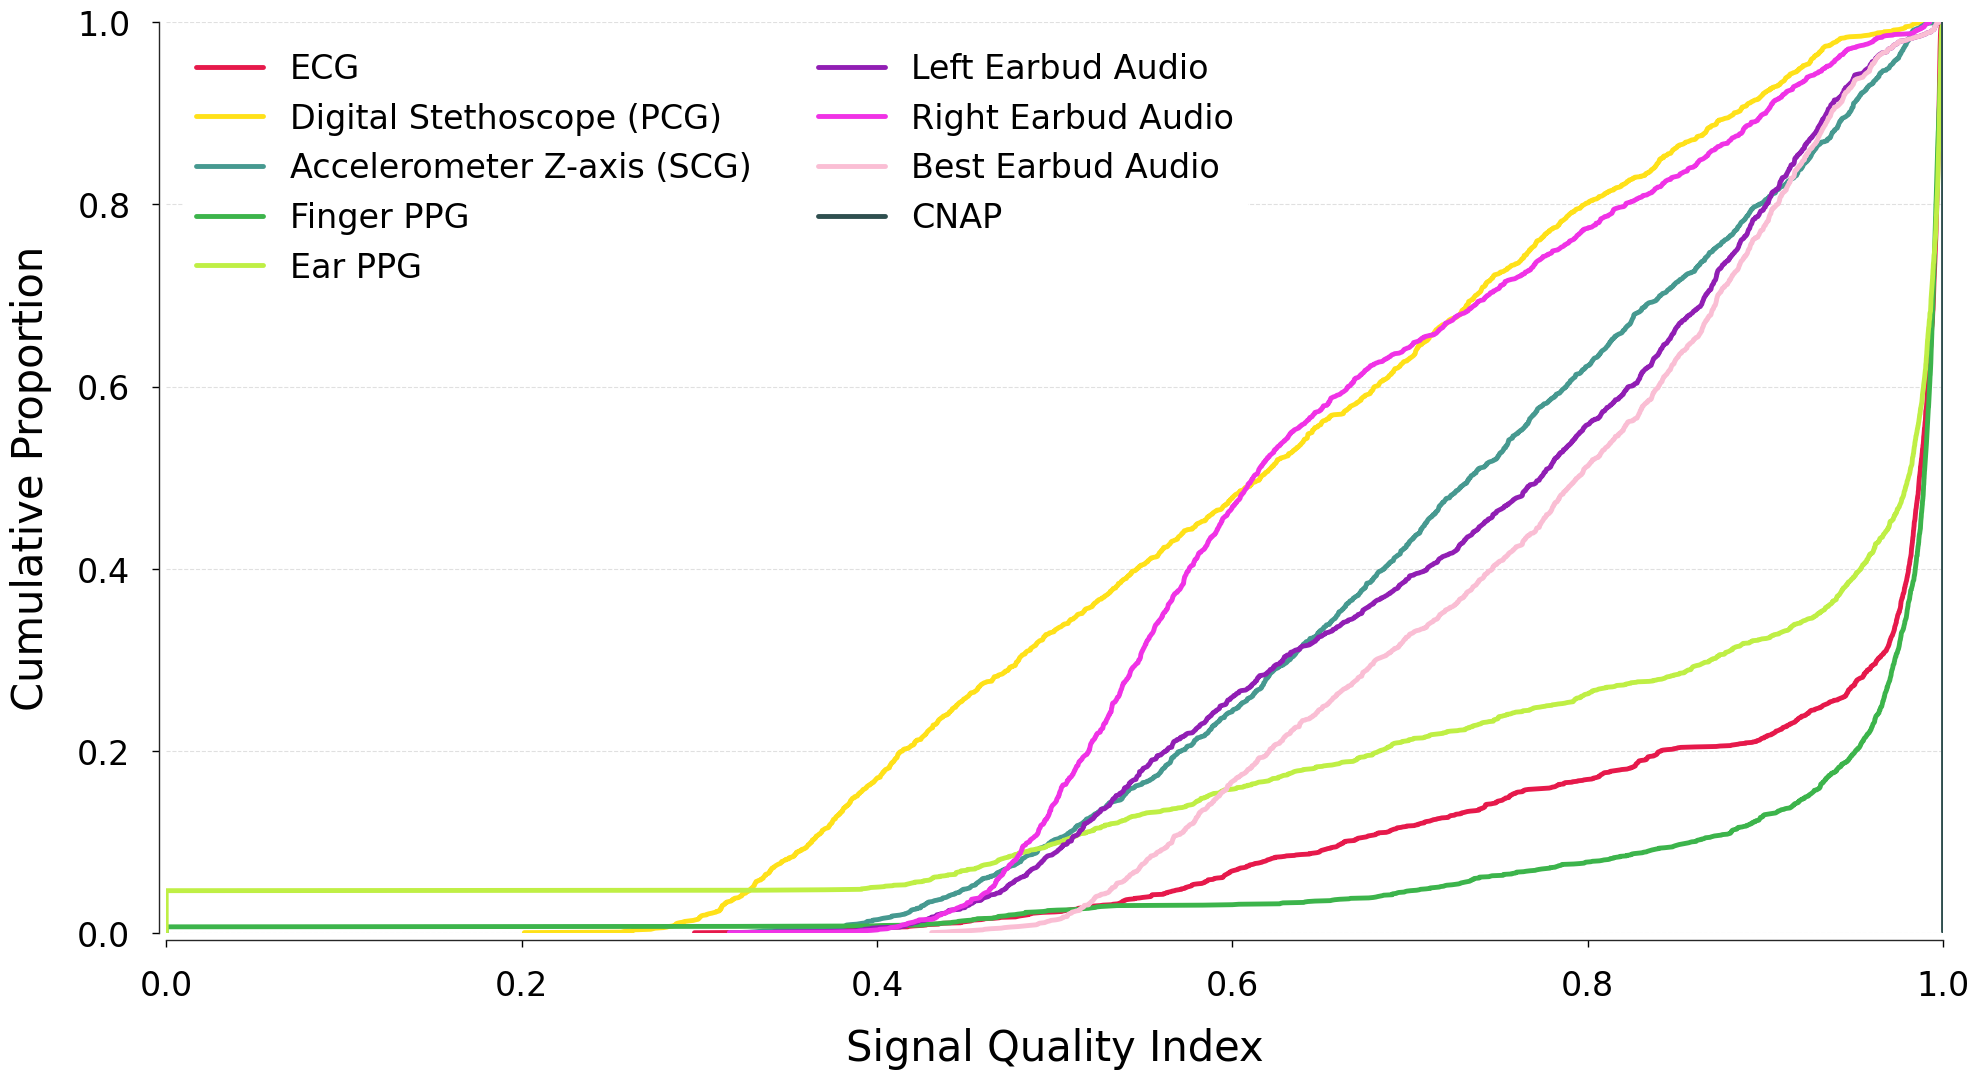

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_5_cdf_sqi.png


In [9]:
SQI_CDF_SIGNALS = [
    'ECG', 'Digital_Stethoscope', 'Accelerometer_Z', 'PPG_Finger', 'PPG_Ear',
    'Earbud_Left', 'Earbud_Right', 'Earbud_Best', 'NIBP',
]
SQI_CDF_COLORS = {
    **SIGNAL_COLORS, 'Earbud_Best': '#FABED4', 'NIBP': '#2F4F4F',
}
SQI_CDF_LABELS = {
    'ECG': 'ECG', 'Digital_Stethoscope': 'Digital Stethoscope (PCG)',
    'Accelerometer_Z': 'Accelerometer Z-axis (SCG)', 'PPG_Finger': 'Finger PPG',
    'PPG_Ear': 'Ear PPG', 'Earbud_Left': 'Left Earbud Audio',
    'Earbud_Right': 'Right Earbud Audio', 'Earbud_Best': 'Best Earbud Audio',
    'NIBP': 'CNAP',
}

sqi_master_df = pd.DataFrame({
    signal: quality_score(all_windows.get(f'{signal}_quality', pd.Series(dtype=float)))
    for signal in SQI_CDF_SIGNALS if signal != 'Earbud_Best'
})
if {'Earbud_Left', 'Earbud_Right'}.issubset(sqi_master_df.columns):
    sqi_master_df['Earbud_Best'] = sqi_master_df[['Earbud_Left', 'Earbud_Right']].max(axis=1)

sns.set_theme(style='ticks', context='paper', font_scale=1.4, font='DejaVu Sans')
plt.rcParams.update({'text.color': 'black', 'axes.labelcolor': 'black',
                      'xtick.color': 'black', 'ytick.color': 'black'})
fig, ax = plt.subplots(figsize=(20, 11))
for signal in SQI_CDF_SIGNALS:
    vals = sqi_master_df[signal].dropna().to_numpy() if signal in sqi_master_df.columns else np.array([])
    vals = vals[(vals >= 0) & (vals <= 1)]
    if len(vals) == 0:
        continue
    sorted_vals = np.sort(vals)
    cdf = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
    ax.plot(sorted_vals, cdf, color=SQI_CDF_COLORS[signal], linewidth=3.5,
            label=SQI_CDF_LABELS[signal])
ax.set_xlabel('Signal Quality Index', fontsize=30, color='black', labelpad=18)
ax.set_ylabel('Cumulative Proportion', fontsize=30, color='black', labelpad=18)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.grid(axis='x', alpha=0)
ax.legend(frameon=True, framealpha=1.0, edgecolor='none', fontsize=24,
          ncol=2, loc='upper left', labelcolor='black')
ax.tick_params(axis='both', labelsize=24, pad=16, colors='black')
sns.despine(trim=True, offset=5)
fig.tight_layout()
fig.savefig(OUT_DIR / 'figure_5_cdf_sqi.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {OUT_DIR / "figure_5_cdf_sqi.png"}')

#### 4.3 Heart Rate Concordance

Figure 6: Correlation between HRs

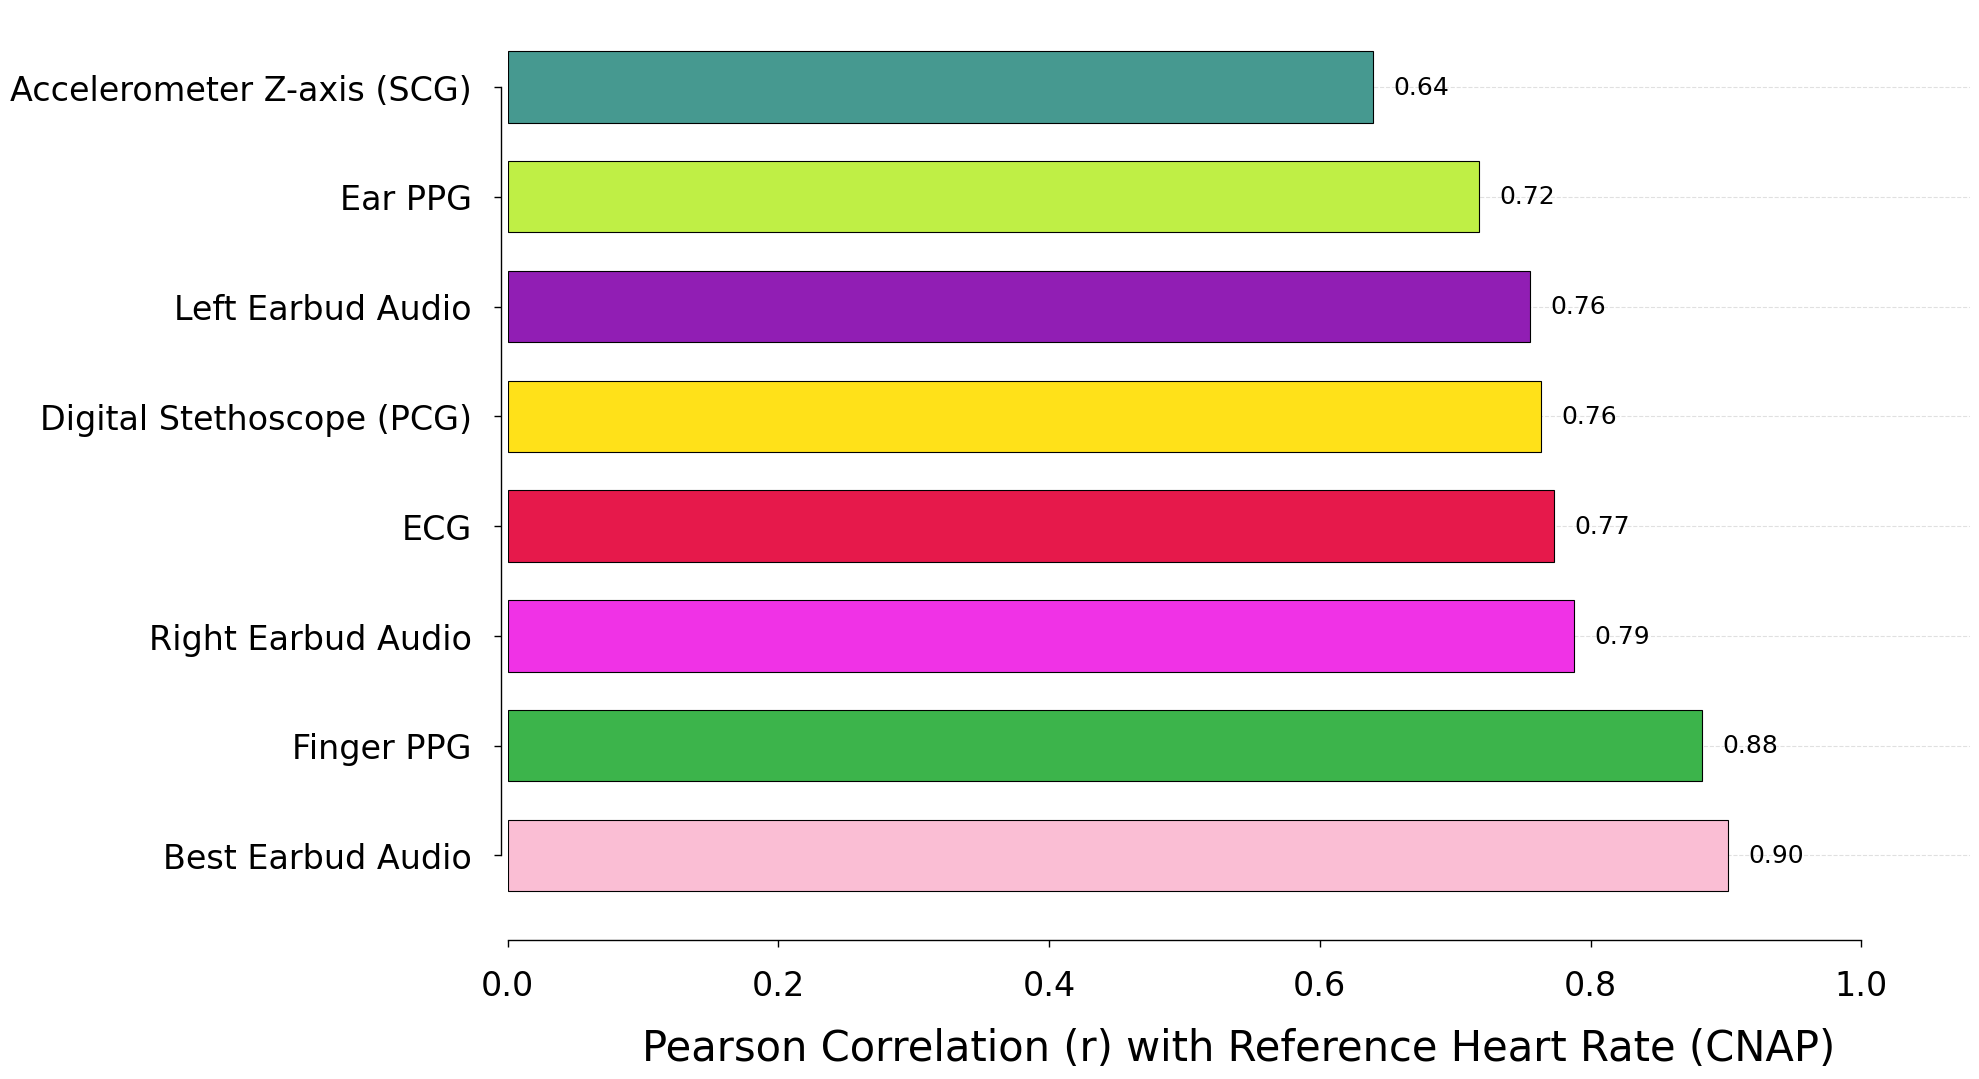

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_6_correlation_hr.png


In [10]:
HR_THRESHOLD = 0.65
HR_SIGNALS = ["ECG", "Digital_Stethoscope", "Accelerometer_Z", "PPG_Finger", "PPG_Ear", "Earbud_Left", "Earbud_Right", "Earbud_Best"]
HR_LABELS = {
    "ECG": "ECG", "Digital_Stethoscope": "Digital Stethoscope (PCG)",
    "Accelerometer_Z": "Accelerometer Z-axis (SCG)", "PPG_Finger": "Finger PPG",
    "PPG_Ear": "Ear PPG", "Earbud_Left": "Left Earbud Audio",
    "Earbud_Right": "Right Earbud Audio", "Earbud_Best": "Best Earbud Audio",
}
HR_COLORS = {
    "ECG": "#E6194B", "Digital_Stethoscope": "#FFE119",
    "Accelerometer_Z": "#469990", "PPG_Finger": "#3CB44B", "PPG_Ear": "#BFEF45",
    "Earbud_Left": "#911EB4", "Earbud_Right": "#F032E6", "Earbud_Best": "#FABED4",
}
hr_paths = sorted(DATA_DIR.glob(f"*/{FIXED_30_FILE}"))
hr_pairs = {signal: [] for signal in HR_SIGNALS}
for path in hr_paths:
    try:
        frame = pd.read_csv(path)
    except Exception as exc:
        print(f"Skipping {path.parent.name}: {exc}")
        continue
    reference_col = "Heart_Rate_midpoint"
    if not {reference_col, "Diastolic_BP_quality", "Systolic_BP_quality"}.issubset(frame.columns):
        continue
    reference_valid = frame["Diastolic_BP_quality"].isin([True, "True", "true", 1, 1.0]) & frame["Systolic_BP_quality"].isin([True, "True", "true", 1, 1.0])
    reference = pd.to_numeric(frame[reference_col], errors="coerce")

    def get_numeric_column(candidates):
        for name in candidates:
            if name in frame.columns:
                return pd.to_numeric(frame[name], errors="coerce")
        return pd.Series(np.nan, index=frame.index, dtype=float)

    left_hr = get_numeric_column(["Earbud_Left_HR_IBI", "Earbud_Left_HR"])
    right_hr = get_numeric_column(["Earbud_Right_HR_IBI", "Earbud_Right_HR"])
    left_quality = quality_score(frame.get("Earbud_Left_quality", pd.Series(np.nan, index=frame.index)))
    right_quality = quality_score(frame.get("Earbud_Right_quality", pd.Series(np.nan, index=frame.index)))
    left_error = (left_hr - reference).abs()
    right_error = (right_hr - reference).abs()
    use_left = left_hr.notna() & (right_hr.isna() | (left_error <= right_error))
    frame["Earbud_Best_HR"] = left_hr.where(use_left, right_hr)
    frame["Earbud_Best_quality"] = left_quality.where(use_left, right_quality)

    for signal in HR_SIGNALS:
        hr = get_numeric_column([f"{signal}_HR_IBI", f"{signal}_HR"])
        quality_col = f"{signal}_quality"
        if quality_col not in frame.columns:
            continue
        sqi = quality_score(frame[quality_col])
        valid = reference_valid & sqi.gt(HR_THRESHOLD) & reference.notna() & hr.notna()
        pair = pd.DataFrame({"reference": reference[valid], "estimate": hr[valid]})
        if not pair.empty:
            hr_pairs[signal].append(pair)

hr_rows = []
for signal, frames in hr_pairs.items():
    if not frames:
        continue
    pooled = pd.concat(frames, ignore_index=True)
    if len(pooled) < 2 or pooled["reference"].std() == 0 or pooled["estimate"].std() == 0:
        continue
    r_value, _ = pearsonr(pooled["estimate"], pooled["reference"])
    hr_rows.append({"signal": signal, "r": float(r_value), "n": len(pooled)})
if not hr_rows:
    raise ValueError("No valid 30-second sensor/CNAP heart-rate pairs were found in available WFDB records.")
hr_concordance = pd.DataFrame(hr_rows).sort_values("r", ascending=True).reset_index(drop=True)
hr_concordance["label"] = hr_concordance["signal"].map(HR_LABELS)
hr_concordance.to_csv(OUT_DIR / "table_hr_pearson_vs_cnap.csv", index=False)

sns.set_theme(style="ticks", context="paper", font_scale=1.4, font="DejaVu Sans")
plt.rcParams.update({"text.color": "black", "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"})
fig, ax = plt.subplots(figsize=(20, 11))
y_positions = np.arange(len(hr_concordance))
r_values = hr_concordance["r"].to_numpy()
signals = hr_concordance["signal"].tolist()
ax.barh(y_positions, r_values, color=[HR_COLORS[signal] for signal in signals], edgecolor="black", linewidth=0.8, height=0.65)
for y, value in zip(y_positions, r_values):
    ax.text(value + 0.015, y, f"{value:.2f}", va="center", ha="left", fontsize=18, color="black")
ax.set_yticks(y_positions)
ax.set_yticklabels(hr_concordance["label"], fontsize=24)
ax.invert_yaxis()
ax.set_xlim(0, 1.08)
ax.set_xlabel("Pearson Correlation (r) with Reference Heart Rate (CNAP)", fontsize=30, color="black", labelpad=18)
ax.set_ylabel("", fontsize=30, color="black", labelpad=18)
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.grid(axis="x", alpha=0)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="both", labelsize=24, pad=16, colors="black")
sns.despine(trim=True, offset=5)
fig.tight_layout()
fig.savefig(OUT_DIR / "figure_6_correlation_hr.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_DIR / 'figure_6_correlation_hr.png'}")

#### 4.4 Pulse Transit Time Concordance

Figure 7: PAT Distributions

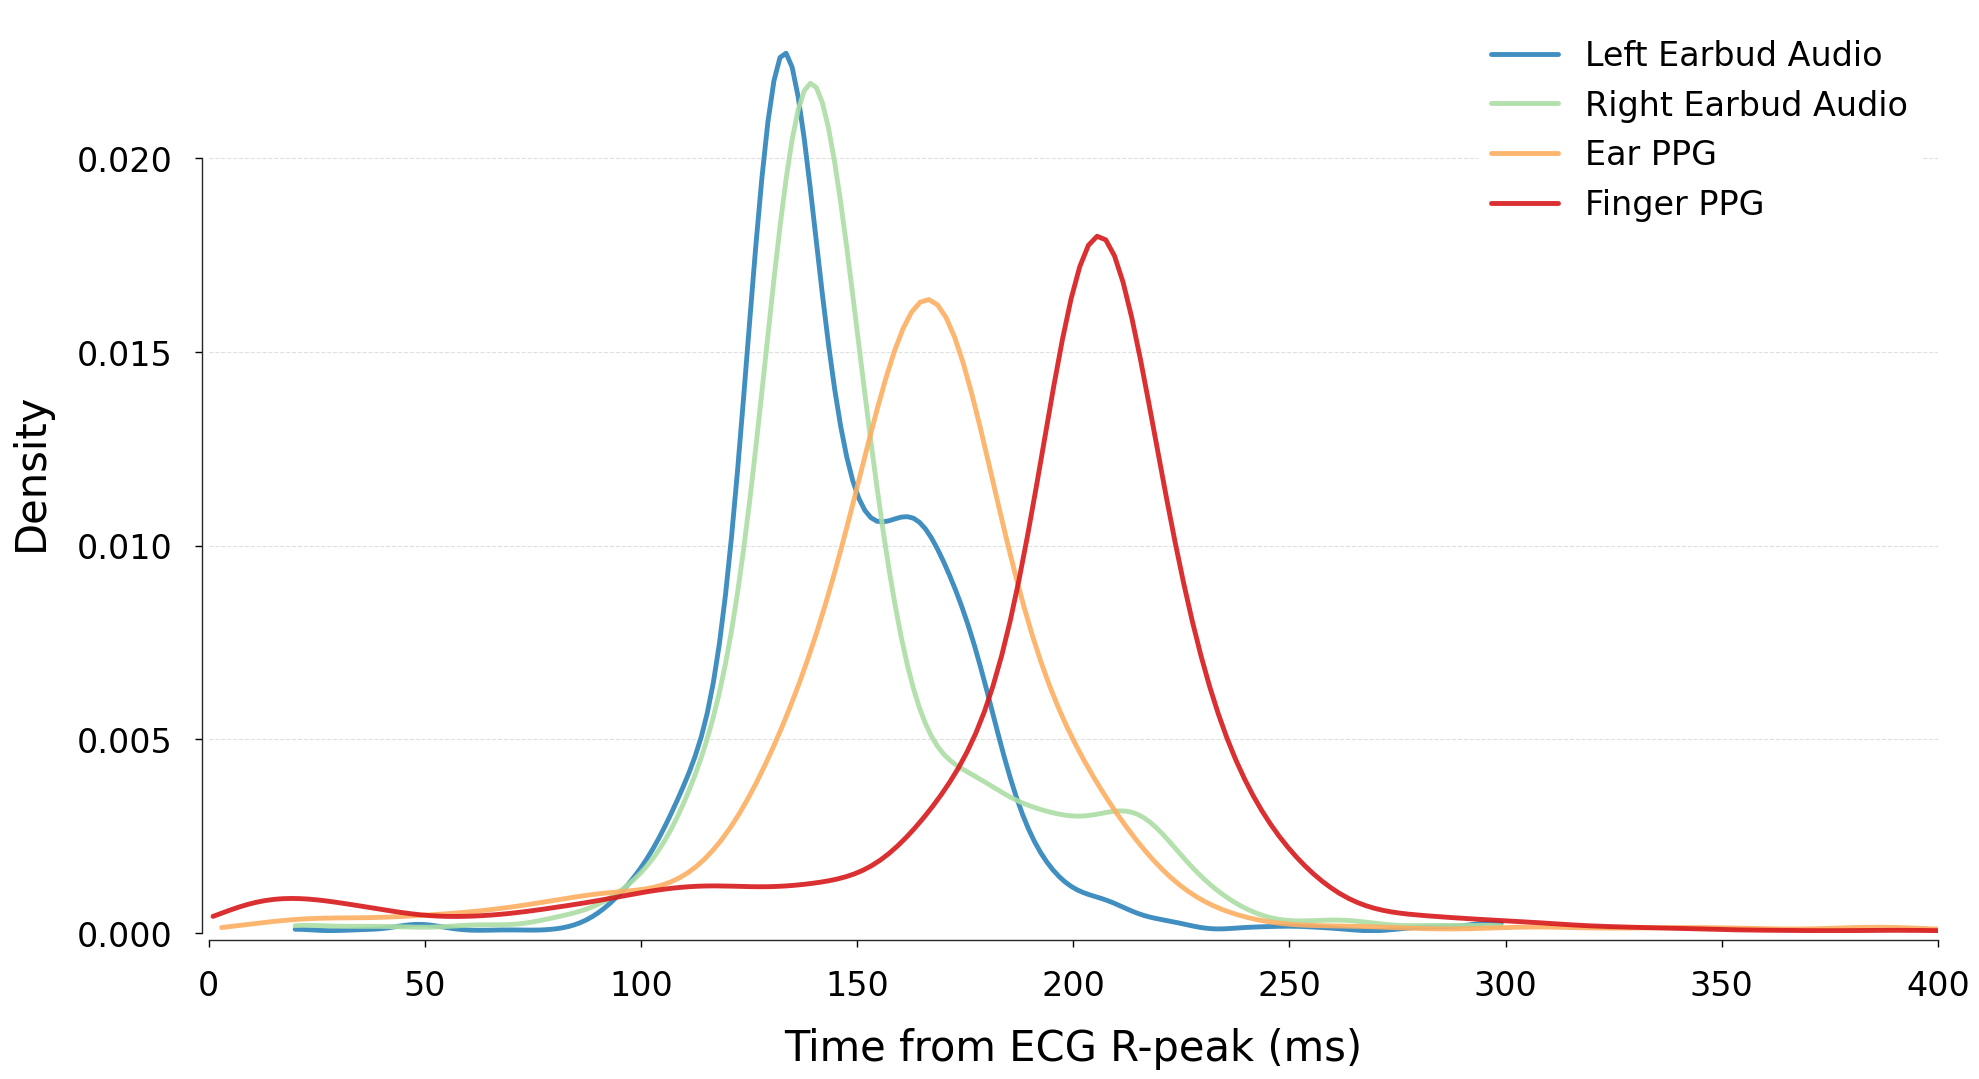

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_7_pat_distributions.png


In [11]:
PAT_THRESHOLD = 0.65
PAT_FS = FS
PAT_OUTPUT = OUT_DIR / "figure_7_pat_distributions.png"
PAT_COLUMNS = {
    "PTT_Earbud_Left_a": ("Earbud_Left_a", "Earbud_Left_quality", "Left Earbud Audio", "#2b83ba"),
    "PTT_Earbud_Right_a": ("Earbud_Right_a", "Earbud_Right_quality", "Right Earbud Audio", "#abdda4"),
    "PTT_PPG_Ear_foot": ("PPG_Ear_foot", "PPG_Ear_quality", "Ear PPG", "#fdae61"),
    "PTT_PPG_Finger_foot": ("PPG_Finger_foot", "PPG_Finger_quality", "Finger PPG", "#d7191c"),
}


def high_quality_mask(series, threshold=PAT_THRESHOLD):
    """Return a mask for valid flags or SQI values meeting the threshold."""
    text = series.astype("string").str.strip().str.lower()
    numeric = pd.to_numeric(series, errors="coerce")
    is_bool = series.map(lambda value: isinstance(value, (bool, np.bool_)))
    bool_true = is_bool & series.fillna(False).astype(bool)
    string_true = text.isin(["true", "1"])
    return bool_true | string_true | numeric.ge(threshold)


pat_records = []
cycle_csvs = sorted(DATA_DIR.glob(f"*/{CYCLE_FILE}"))
if not cycle_csvs:
    raise FileNotFoundError(f"No cardiac-cycle CSVs found under {DATA_DIR}.")
for csv_path in cycle_csvs:
    session = csv_path.parent.name
    try:
        cycles = pd.read_csv(csv_path)
    except Exception as exc:
        print(f"Skipping {session}: {exc}")
        continue
    if not {"ECG_R_peak", "ECG_quality"}.issubset(cycles.columns):
        continue
    r_peak = pd.to_numeric(cycles["ECG_R_peak"], errors="coerce")
    ecg_valid = high_quality_mask(cycles["ECG_quality"]) & r_peak.notna()
    for pat_name, (fiducial_col, quality_col, label, color) in PAT_COLUMNS.items():
        if fiducial_col not in cycles.columns or quality_col not in cycles.columns:
            continue
        distal = pd.to_numeric(cycles[fiducial_col], errors="coerce")
        distal_valid = high_quality_mask(cycles[quality_col]) & distal.notna()
        pat_samples = (distal - r_peak).where(ecg_valid & distal_valid)
        valid_samples = pat_samples.where(pat_samples > 0).dropna()
        if not valid_samples.empty:
            pat_records.append(pd.DataFrame({
                "session": session,
                "signal": pat_name,
                "pat_ms": valid_samples.to_numpy() / PAT_FS * 1000.0,
            }))
if not pat_records:
    raise ValueError("No positive, quality-filtered PAT measurements were found in available WFDB sessions.")
pat_distribution = pd.concat(pat_records, ignore_index=True)

sns.set_theme(style="ticks", context="paper", font_scale=1.4, font="DejaVu Sans")
plt.rcParams.update({"text.color": "black", "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"})
fig, ax = plt.subplots(figsize=(20, 11))
for pat_name, (_, _, label, color) in PAT_COLUMNS.items():
    values = pat_distribution.loc[pat_distribution["signal"].eq(pat_name), "pat_ms"]
    if values.empty:
        print(f"No valid data for {label}; skipping its curve.")
        continue
    sns.kdeplot(values, ax=ax, color=color, label=label, linewidth=3.5, alpha=0.9, clip=(0, 400), cut=0)
ax.set_xlabel("Time from ECG R-peak (ms)", fontsize=30, color="black", labelpad=18)
ax.set_ylabel("Density", fontsize=30, color="black", labelpad=18)
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.grid(axis="x", alpha=0)
ax.set_xlim(0, 400)
ax.legend(loc="upper right", framealpha=1.0, edgecolor="none", fontsize=24, labelcolor="black")
ax.tick_params(axis="both", labelsize=24, pad=16, colors="black")
sns.despine(trim=True, offset=5)
fig.tight_layout()
fig.savefig(PAT_OUTPUT, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {PAT_OUTPUT}")